# Кластеризация и техники понижения размерности. Часть II

## Меры качества кластеризации. Практика.

### Задание 4.1
Так как изначально данные были представлены для решения задачи классификации, то они находятся в разных файлах (обучающая и тестовая выборки в соотношении 70/30). Соедините признаки так, чтобы сначала шла обучающая выборка, а затем — тестовая, и отдельно соедините значения целевых переменных (разумеется, в том же порядке).

Какая размерность получилась у набора данных с признаками?

In [2]:
import pandas as pd

# 1. Загружаем признаки
X_train = pd.read_csv('data/train.txt', sep=r'\s+', header=None)
X_test = pd.read_csv('data/test.txt', sep=r'\s+', header=None)

# 2. Объединяем признаки (сначала train, потом test)
X = pd.concat([X_train, X_test], ignore_index=True)

# 3. Загружаем целевую переменную
y_train = pd.read_csv('data/train_labels.txt', sep=r'\s+', header=None)
y_test = pd.read_csv('data/test_labels.txt', sep=r'\s+', header=None)

# 4. Объединяем метки
y = pd.concat([y_train, y_test], ignore_index=True)

# 5. Выводим размерность набора с признаками
print(f"Размерность набора данных с признаками: {X.shape}")

Размерность набора данных с признаками: (10299, 561)


### Задание 4.2
Теперь найдите число различных активностей, то есть на сколько кластеров в идеале должны разделиться наблюдения.

In [3]:
# 1. Смотрим на уникальные значения в целевой переменной
unique_labels = y[0].unique()

# 2. Выводим их количество и сами значения
print(f"Количество различных активностей (кластеров): {len(unique_labels)}")
print(f"Уникальные метки: {unique_labels}")

Количество различных активностей (кластеров): 6
Уникальные метки: [5 4 6 1 3 2]


### Задание 4.3
Далее необходимо отмасштабировать признаки. Будем использовать для этого алгоритм StandardScaler. Примените его ко всем значениям признаков и впишите в качестве ответа значение первого признака для первого объекта, предварительно округлив его до двух знаков после точки-разделителя.

In [4]:
from sklearn.preprocessing import StandardScaler

# 1. Инициализируем скейлер
scaler = StandardScaler()

# 2. Применяем масштабирование ко всем признакам
X_scaled = scaler.fit_transform(X)

# 3. Берем первое значение (первая строка, первый столбец) и округляем
first_value = X_scaled[0, 0]

print(f"Первое значение первого признака после масштабирования: {round(first_value, 2)}")

Первое значение первого признака после масштабирования: 0.21


### Задание 4.4
Пора переходить к кластеризации. Для начала определите оптимальное количество кластеров, используя внутренние меры кластеризации. Используйте все известные вам коэффициенты, реализуемые в библиотеке sklearn: коэффициент силуэта, индекс Калински — Харабаса и индекс Дэвиса — Болдина. В качестве алгоритма возьмите k-means++, в качестве значения параметра random_state — число 42.

Выведите оптимальное количество кластеров для каждой метрики, перебирая значения от 2 до 9 включительно. Также введите значение каждой метрики, округлённое до двух знаков после точки-разделителя.

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import pandas as pd

# Создаем списки для хранения результатов
results = []

K_range = range(2, 10)

for k in K_range:
    # Обучаем модель
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    
    # Считаем метрики
    sil_score = silhouette_score(X_scaled, labels)
    ch_score = calinski_harabasz_score(X_scaled, labels)
    db_score = davies_bouldin_score(X_scaled, labels)
    
    # Сохраняем в список
    results.append({
        'k': k,
        'Silhouette': sil_score,
        'Calinski-Harabasz': ch_score,
        'Davies-Bouldin': db_score
    })

# Переводим в DataFrame для красивого вывода
df_metrics = pd.DataFrame(results).set_index('k')

# Округляем для вывода
print("Значения метрик для каждого k:")
print(df_metrics.round(2))

# Находим оптимальное k для каждой метрики
best_sil_k = df_metrics['Silhouette'].idxmax()
best_ch_k = df_metrics['Calinski-Harabasz'].idxmax()
best_db_k = df_metrics['Davies-Bouldin'].idxmin()

print(f"\n--- Оптимальное количество кластеров ---")
print(f"По коэффициенту силуэта (максимум): k = {best_sil_k} (значение: {df_metrics.loc[best_sil_k, 'Silhouette']:.2f})")
print(f"По индексу Калински-Харабаса (максимум): k = {best_ch_k} (значение: {df_metrics.loc[best_ch_k, 'Calinski-Harabasz']:.2f})")
print(f"По индексу Дэвиса-Болдина (минимум): k = {best_db_k} (значение: {df_metrics.loc[best_db_k, 'Davies-Bouldin']:.2f})")

Значения метрик для каждого k:
   Silhouette  Calinski-Harabasz  Davies-Bouldin
k                                               
2        0.39            7880.81            1.07
3        0.32            5034.48            1.79
4        0.15            3696.34            2.34
5        0.13            3027.32            2.41
6        0.11            2556.54            2.38
7        0.08            2217.86            2.68
8        0.07            1975.21            2.61
9        0.07            1790.14            2.62

--- Оптимальное количество кластеров ---
По коэффициенту силуэта (максимум): k = 2 (значение: 0.39)
По индексу Калински-Харабаса (максимум): k = 2 (значение: 7880.81)
По индексу Дэвиса-Болдина (минимум): k = 2 (значение: 1.07)


### Задание 4.5
Теперь давайте оценим качество кластеризации с точки зрения внешних мер. Реализуйте кластеризацию с помощью классической версии алгоритма k-means. Пусть количество кластеров будет соответствовать количеству активностей. Задайте следующие значения параметров: random_state=42, init='random'.

В качестве ответов введите значения получившихся мер, предварительно округлив их до двух знаков после точки-разделителя.

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import homogeneity_score, completeness_score, adjusted_rand_score

# 1. Определяем количество активностей (кластеров)
n_activities = y[0].nunique()

# 2. Обучаем K-Means с параметрами из задания
kmeans_ext = KMeans(n_clusters=n_activities, init='random', random_state=42, n_init=10)
labels_ext = kmeans_ext.fit_predict(X_scaled)

# 3. Считаем нужные метрики
homogeneity = homogeneity_score(y[0], labels_ext)
completeness = completeness_score(y[0], labels_ext)
ari = adjusted_rand_score(y[0], labels_ext)

# 4. Выводим результаты, округленные до двух знаков
print(f"Количество кластеров: {n_activities}")
print(f"Однородность (Homogeneity): {round(homogeneity, 2)}")
print(f"Полнота (Completeness): {round(completeness, 2)}")
print(f"Adjusted Rand Index (ARI): {round(ari, 2)}")

Количество кластеров: 6
Однородность (Homogeneity): 0.54
Полнота (Completeness): 0.58
Adjusted Rand Index (ARI): 0.42


### Задание 4.6
Выясните, к каким кластерам были преимущественно отнесены различные активности (т. е. в какой кластер попало большинство наблюдений с этой активностью). Нумерацию кластеров начинайте с 1.

In [7]:
import pandas as pd

# 1. Создаем кросс-таблицу (матрицу сопряженности)
# Индекс — это истинные активности (от 1 до 6)
# Столбцы — это предсказанные кластеры (0, 1, 2...)
# Прибавляем 1 к меткам, чтобы кластеры нумеровались с 1, как просят в задании
crosstab = pd.crosstab(
    index=y[0], 
    columns=labels_ext + 1
)

# 2. Выводим таблицу
print("Матрица сопряженности (строки - истинные активности, столбцы - кластеры):")
display(crosstab)

# 3. Находим доминирующий кластер для каждой активности
print("\n--- Преимущественный кластер для каждой активности ---")
for activity in crosstab.index:
    # Находим столбец (кластер) с максимальным значением в строке
    dominant_cluster = crosstab.loc[activity].idxmax()
    count = crosstab.loc[activity].max()
    print(f"Активность {activity}: преимущественно в кластере {dominant_cluster} (попаданий: {count})")
    

Матрица сопряженности (строки - истинные активности, столбцы - кластеры):


col_0,1,2,3,4,5,6
0,,,,,,
1,741,897,0,0,84,0
2,297,1236,2,0,9,0
3,882,310,0,0,214,0
4,0,1,447,91,0,1238
5,0,0,560,0,0,1346
6,0,5,329,1556,0,54



--- Преимущественный кластер для каждой активности ---
Активность 1: преимущественно в кластере 2 (попаданий: 897)
Активность 2: преимущественно в кластере 2 (попаданий: 1236)
Активность 3: преимущественно в кластере 1 (попаданий: 882)
Активность 4: преимущественно в кластере 6 (попаданий: 1238)
Активность 5: преимущественно в кластере 6 (попаданий: 1346)
Активность 6: преимущественно в кластере 4 (попаданий: 1556)


### Задание 4.7
Теперь попробуйте реализовать алгоритм k-means для двух кластеров (для того числа активностей, которое является оптимальным с точки зрения внутренних мер) и снова посмотреть, как алгоритм разобьёт активности по кластерам. Как и в предыдущем задании, нумерацию кластеров начинайте с 1.

In [8]:
from sklearn.cluster import KMeans
import pandas as pd

# 1. Обучаем K-Means для 2 кластеров
kmeans_2 = KMeans(n_clusters=2, init='random', random_state=42, n_init=10)
labels_2 = kmeans_2.fit_predict(X_scaled)

# 2. Строим кросс-таблицу (прибавляем 1 к меткам)
crosstab_2 = pd.crosstab(
    index=y[0], 
    columns=labels_2 + 1
)

print("Матрица сопряженности для 2 кластеров:")
display(crosstab_2)

# 3. Выводим доминирующий кластер для каждой активности
print("\n--- Преимущественный кластер для каждой активности ---")
for activity in crosstab_2.index:
    dominant_cluster = crosstab_2.loc[activity].idxmax()
    print(f"Активность {activity}: кластер {dominant_cluster}")

Матрица сопряженности для 2 кластеров:


col_0,1,2
0,,
1,1722,0
2,1536,8
3,1406,0
4,3,1774
5,0,1906
6,12,1932



--- Преимущественный кластер для каждой активности ---
Активность 1: кластер 1
Активность 2: кластер 1
Активность 3: кластер 1
Активность 4: кластер 2
Активность 5: кластер 2
Активность 6: кластер 2


### Задание 4.8
Вычислите значение полноты для разбиения на два кластера алгоритмом k-means. Ответ округлите до двух знаков после точки-разделителя.

In [9]:
from sklearn.metrics import completeness_score

# Считаем полноту (Completeness) для 2 кластеров
completeness_2 = completeness_score(y[0], labels_2)

print(f"Полнота (Completeness) для 2 кластеров: {round(completeness_2, 2)}")

Полнота (Completeness) для 2 кластеров: 0.98


### Задание 4.10
Давайте сравним полученный результат с агломеративной иерархической кластеризацией. Реализуйте её также для двух кластеров и вычислите значение полноты.

In [10]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import completeness_score

# 1. Обучаем агломеративную кластеризацию для 2 кластеров
agg_model_2 = AgglomerativeClustering(n_clusters=2)
labels_agg_2 = agg_model_2.fit_predict(X_scaled)

# 2. Считаем полноту (Completeness)
completeness_agg_2 = completeness_score(y[0], labels_agg_2)

print(f"Полнота (Completeness) для агломеративной кластеризации (2 кластера): {round(completeness_agg_2, 2)}")

Полнота (Completeness) для агломеративной кластеризации (2 кластера): 1.0


## PCA

На первом шаге необходимо стандартизировать данные. Это делается по следующей формуле:

In [1]:
import numpy as np
import pandas as pd
A = np.matrix([[1,2,3,4],
               [5,5,6,7],
               [1,4,2,3],
               [5,3,2,1],
               [8,1,2,2]])

df = pd.DataFrame(A,columns  = ['x1','x2','x3','x4'])
df_std  = (df - df.mean()) / (df.std())

Перейдём ко второму шагу. Теперь нам необходимо вычислить ковариационную матрицу для наших стандартизированных данных. Для этого будем пользоваться следующей формулой:

In [2]:
cov_mat = np.cov(df_std.T)
cov_mat

array([[ 1.        , -0.31622777,  0.04811252, -0.18098843],
       [-0.31622777,  1.        ,  0.63900965,  0.61812254],
       [ 0.04811252,  0.63900965,  1.        ,  0.94044349],
       [-0.18098843,  0.61812254,  0.94044349,  1.        ]])

Следующим шагом нам необходимо вычислить собственные значения и собственные векторы для матрицы. Для этого надо решить уравнение:

In [5]:
eigen_val, eigen_vectors = np.linalg.eig(cov_mat)
eigen_vectors

array([[ 0.16195986, -0.91705888, -0.30707099,  0.19616173],
       [-0.52404813,  0.20692161, -0.81731886,  0.12061043],
       [-0.58589647, -0.3205394 ,  0.1882497 , -0.72009851],
       [-0.59654663, -0.11593512,  0.44973251,  0.65454704]])

Теперь нам необходимо выбрать два собственных вектора, так как в итоге мы хотим получить две компоненты. Нужно взять векторы с наибольшими собственными значениями. При нахождении собственных векторов в Python они выводятся в соответствии с убыванием соответствующих собственных значений, поэтому берём первые два вектора:

Осталось только найти главные компоненты. Для этого перемножаем матрицу стандартизированных признаков на матрицу с собственными векторами и получаем матрицу главных компонент:

### Делать я это не буду, формулу они готовую не дали
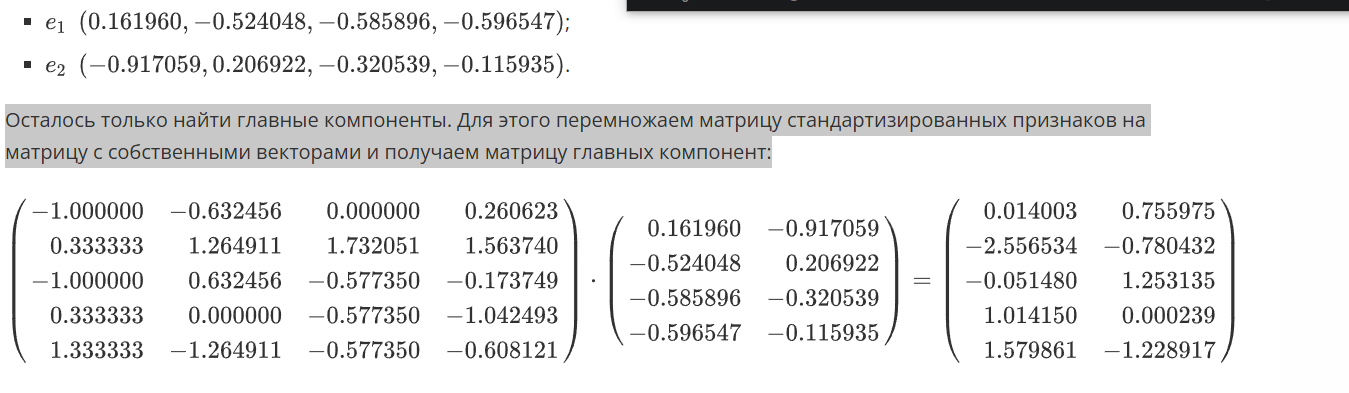


Таким образом, мы получили две главных компоненты. Можно проверить, получили ли бы мы тот же результат, если бы воспользовались сразу готовым алгоритмом на Python — PCA.

В параметр n_components в качестве значения можно передать количество необходимых компонентов или минимально допустимую объяснённую дисперсию в виде десятичной дроби. Например, если нам нужно столько компонент, чтобы они объясняли не менее 90 % разброса данных, то мы запишем n_components = 0.9.

In [6]:
#импортируем нужный алгоритм

from sklearn.decomposition import PCA
#определяем метод главных компонент с двумя компонентами
pca = PCA(n_components=2)
#обучаем алгоритм на наших данных
principalComponents = pca.fit_transform(df_std)

### Задание 5.1
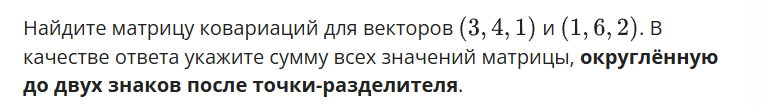

In [7]:
import numpy as np

# 1. Задаем векторы
X = np.array([3, 4, 1])
Y = np.array([1, 6, 2])

# 2. Объединяем их в матрицу, где строки - это признаки (X и Y), 
# а столбцы - это наблюдения (3 штуки)
# np.vstack "склеивает" векторы по вертикали
data = np.vstack((X, Y))

# 3. Считаем матрицу ковариаций
# По умолчанию np.cov использует выборочную ковариацию (делит на n-1), как в математике
cov_matrix = np.cov(data)

print("Матрица ковариаций:")
print(cov_matrix)

# 4. Считаем сумму всех элементов матрицы
total_sum = cov_matrix.sum()

print(f"\nСумма всех значений: {total_sum}")
print(f"Округленный ответ: {round(total_sum, 2)}")

Матрица ковариаций:
[[2.33333333 2.5       ]
 [2.5        7.        ]]

Сумма всех значений: 14.333333333333334
Округленный ответ: 14.33


### Задание 5.4
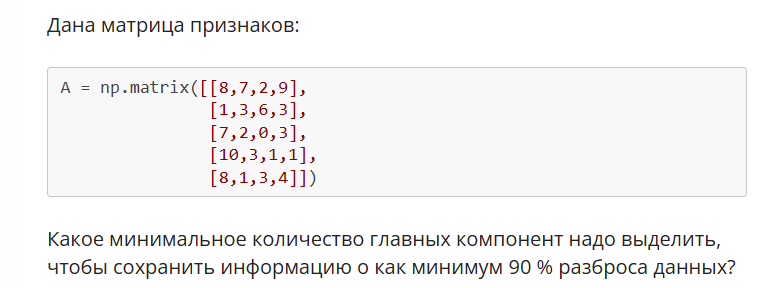

In [8]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Задаем матрицу из задания
A = np.matrix([[8,7,2,9],
               [1,3,6,3],
               [7,2,0,3],
               [10,3,1,1],
               [8,1,3,4]])

# 2. Стандартизируем данные (mean=0, std=1) 
# Обязательно приводим matrix к array для корректной работы scaler
A_scaled = StandardScaler().fit_transform(np.array(A))

# 3. Обучаем PCA (сначала берем все возможные компоненты)
pca = PCA(n_components=4)
pca.fit(A_scaled)

# 4. Смотрим на долю объясненной дисперсии для каждой компоненты
explained_variance = pca.explained_variance_ratio_

print("Доля объясненной дисперсии по компонентам:")
for i, var in enumerate(explained_variance, 1):
    print(f"Компонента {i}: {var:.4f} ({var*100:.2f}%)")

# 5. Считаем накопленную сумму (cumulative sum) и ищем, где она превысит 90% (0.9)
cumulative_variance = np.cumsum(explained_variance)

print("\nНакопленная дисперсия:")
for i, var in enumerate(cumulative_variance, 1):
    print(f"{i} компоненты: {var:.4f} ({var*100:.2f}%)")

# Находим минимальное число компонент для >90%
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1
print(f"\nМинимальное количество компонент для сохранения 90% разброса: {n_components_90}")

Доля объясненной дисперсии по компонентам:
Компонента 1: 0.4618 (46.18%)
Компонента 2: 0.4342 (43.42%)
Компонента 3: 0.0592 (5.92%)
Компонента 4: 0.0448 (4.48%)

Накопленная дисперсия:
1 компоненты: 0.4618 (46.18%)
2 компоненты: 0.8960 (89.60%)
3 компоненты: 0.9552 (95.52%)
4 компоненты: 1.0000 (100.00%)

Минимальное количество компонент для сохранения 90% разброса: 3


## SVD и t-SNE

### Задание 6.1
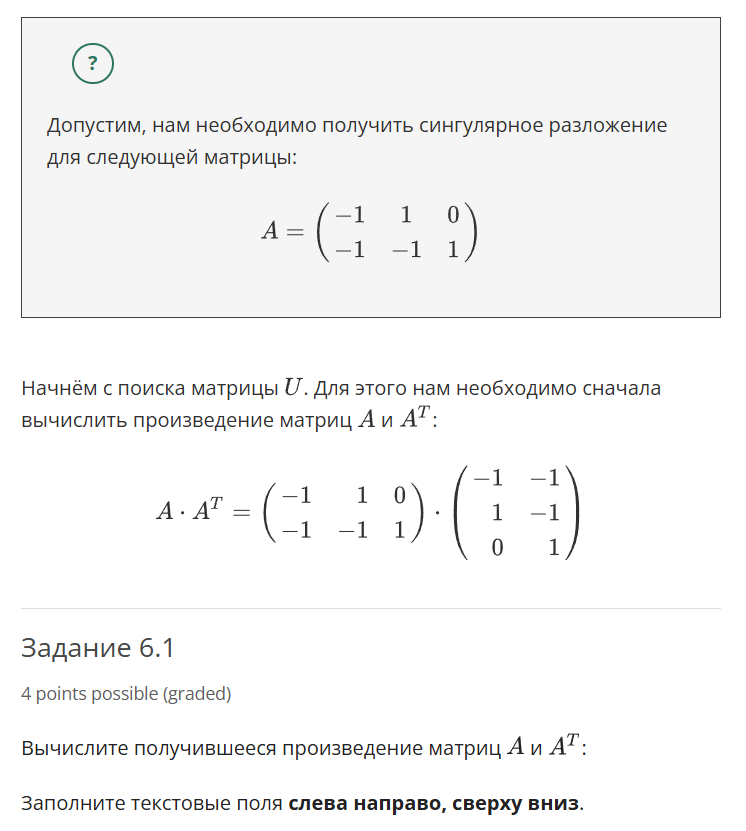

Для того чтобы реализовать сингулярное разложение с помощью библиотеки sklearn, необходимо использовать алгоритм TruncatedSVD(), в который передаётся n_components в качестве параметра, определяющего количество итоговых компонент:

In [12]:
# Импортируем класс
from sklearn.decomposition import TruncatedSVD

# создаём объект класса TruncatedSVD
# n_components — размерность нового пространства, n_iter — количество итераций
svd = TruncatedSVD(n_components=5, n_iter=7, random_state=42)

# обучаем модель на данных X
#svd.fit(X)
#Не обучится, данных нет

Для реализации t-SNE в sklearn понадобится алгоритм TSNE():

In [14]:
# импортируем класс TSNE из модуля manifold библиотеки sklearn
from sklearn.manifold import TSNE
# создаём объект класса TSNE
# n_components — размерность нового пространства
tsne = TSNE(n_components=2, perplexity=30, max_iter=500, random_state=42)
# обучаем модель на данных X и применяем к матрице X уменьшение размерности
#tsne.fit_transform(X)
#Не обучится, данных нет

## Снижение размерности. Практика.

In [15]:
# Загружаем необходимые библиотеки и данные 
import numpy as np                  
import pandas as pd                 
import matplotlib.pyplot as plt     
import seaborn as sns               
import sklearn                      

In [16]:
c_df = pd.read_csv('data/Country-data.csv')
display(c_df.head())
display(c_df.info())

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 14.5 KB


None

### Задание 7.1

Каково максимальное значение показателя средней продолжительности жизни среди представленных стран? Ответ округлите до одного знака после точки-разделителя.

In [17]:
# Находим максимальное значение в столбце life_expec
max_life_expec = c_df['life_expec'].max()

print(f"Максимальная продолжительность жизни: {round(max_life_expec, 1)}")

Максимальная продолжительность жизни: 82.8


### Задание 7.2
Чтобы получить более качественные результаты, необходимо стандартизировать данные. Используйте для этого StandardScaler. Примените его ко всем значениям признаков и впишите в качестве ответа значение первого признака для первого объекта (таким образом можно будет проверить, что вы всё сделали корректно). Ответ округлите до двух знаков после точки-разделителя.

In [18]:
from sklearn.preprocessing import StandardScaler

# 1. Отделяем текстовую колонку (названия стран)
# Удаляем 'country', остальные колонки — числовые признаки
X_numeric = c_df.drop(columns=['country'])

# 2. Инициализируем и применяем StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_numeric)

# 3. Выводим первое значение первого признака (первая строка, первый столбец)
first_value = X_scaled[0, 0]

print(f"Первое значение первого признака: {round(first_value, 2)}")

Первое значение первого признака: 1.29


### Задание 7.3
Как вы помните, нет смысла использовать сильно связанные друг с другом признаки, так как их можно преобразовать в один и таким образом уменьшить общее количество признаков. Давайте выясним, есть ли в данных такие признаки.

Постройте матрицу корреляций для всех признаков. Найдите максимальный коэффициент корреляции. Запишите его в качестве ответа, предварительно округлив до двух знаков после точки-разделителя.

In [19]:
# 1. Строим матрицу корреляций (только для числовых признаков, без country)
corr_matrix = c_df.drop(columns=['country']).corr()

# 2. Находим максимальное значение среди разных признаков (исключая диагональ)
# Для этого временно обнуляем диагональ или используем np.triu
import numpy as np

# Берем только верхний треугольник матрицы (чтобы не дублировать значения)
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Максимальное положительное значение
max_corr = upper_triangle.max().max()

# Максимальное по модулю значение (часто именно его имеют в виду)
max_abs_corr = upper_triangle.abs().max().max()

print(f"Максимальный коэффициент корреляции (прямой): {round(max_corr, 2)}")
print(f"Максимальный коэффициент корреляции (по модулю): {round(max_abs_corr, 2)}")

Максимальный коэффициент корреляции (прямой): 0.9
Максимальный коэффициент корреляции (по модулю): 0.9


### Задание 7.4
Теперь понизим размерность данных — возьмём для этого метод главных компонент (PCA) как самый простой и популярный.

Найдите минимальное число компонент, которые суммарно могут объяснить как минимум 90 % разброса данных.

In [20]:
from sklearn.decomposition import PCA
import numpy as np

# 1. Обучаем PCA на наших масштабированных данных (X_scaled)
pca = PCA()
pca.fit(X_scaled)

# 2. Смотрим на накопленную сумму объясненной дисперсии
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# 3. Выводим, сколько компонент объясняют больше 90% (0.9)
for i, var in enumerate(cumulative_variance, start=1):
    print(f"{i} компонент(ы): {var*100:.2f}%")
    if var >= 0.90:
        print(f"\nОптимальное число компонент для 90% разброса: {i}")
        break

1 компонент(ы): 45.95%
2 компонент(ы): 63.13%
3 компонент(ы): 76.14%
4 компонент(ы): 87.19%
5 компонент(ы): 94.53%

Оптимальное число компонент для 90% разброса: 5


### Задание 7.6
Как вы помните, при создании компонент с помощью PCA они должны получиться независимыми, то есть мы не должны теперь наблюдать высоких коэффициентов корреляции.

Постройте матрицу корреляций. Сколько значений в ней превышают 0.001, не считая единичных значений на главной диагонали?

In [25]:
import numpy as np
import pandas as pd

# 1. Сохраняем результат PCA
X_pca = pca.transform(X_scaled)

# 2. Строим матрицу корреляций в pandas
corr_df = pd.DataFrame(X_pca).corr()

# 3. Обнуляем диагональ напрямую в pandas
# (np.fill_diagonal требует массив, а здесь мы идем по индексам)
for i in range(len(corr_df)):
    corr_df.iloc[i, i] = 0

# 4. Считаем количество значений по модулю > 0.001
count_above_threshold = (corr_df.abs() > 0.001).sum().sum()

print(f"Количество значений > 0.001 (без диагонали): {count_above_threshold}")

Количество значений > 0.001 (без диагонали): 0


### Задание 7.7
Теперь, когда мы уменьшили размерность данных, можно переходить к кластеризации. Подберите оптимальное количество кластеров с помощью коэффициента силуэта, перебирая возможные значения от 2 до 10 включительно. Для кластеризации используйте алгоритм k-means++. В качестве значения параметра random_state возьмите число 1.

Судя по полученным результатам, сколько кластеров лучше всего взять?

Кластеров: 2, Silhouette Score: 0.2874
Кластеров: 3, Silhouette Score: 0.2833
Кластеров: 4, Silhouette Score: 0.3004
Кластеров: 5, Silhouette Score: 0.2224
Кластеров: 6, Silhouette Score: 0.2655
Кластеров: 7, Silhouette Score: 0.2073
Кластеров: 8, Silhouette Score: 0.2462
Кластеров: 9, Silhouette Score: 0.2137
Кластеров: 10, Silhouette Score: 0.2213

Оптимальное количество кластеров (максимальный силуэт): 4


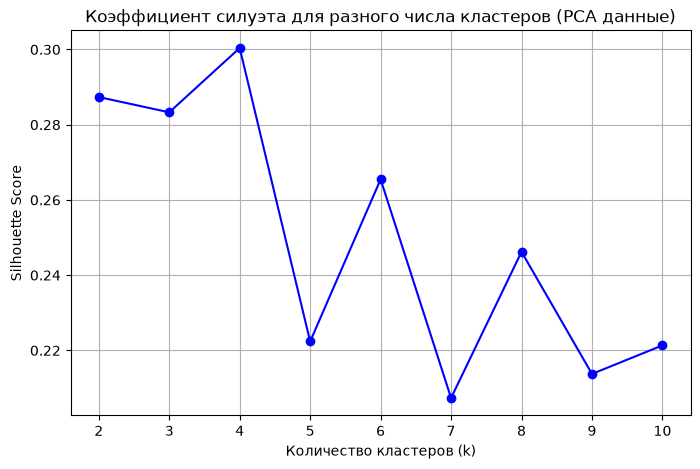

In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Создаем пустой список для хранения результатов
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    # Обучаем K-Means с параметрами из задания
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=1, n_init=10)
    
    # Используем данные после PCA (X_pca)
    labels = kmeans.fit_predict(X_pca)
    
    # Считаем коэффициент силуэта
    score = silhouette_score(X_pca, labels)
    silhouette_scores.append(score)
    print(f"Кластеров: {k}, Silhouette Score: {score:.4f}")

# Находим k с максимальным силуэтом
best_k = K_range[silhouette_scores.index(max(silhouette_scores))]
print(f"\nОптимальное количество кластеров (максимальный силуэт): {best_k}")

# Строим график для наглядности
plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_scores, marker='o', linestyle='-', color='b')
plt.title('Коэффициент силуэта для разного числа кластеров (PCA данные)')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette Score')
plt.xticks(K_range)
plt.grid(True)
plt.show()

### Задание 7.8
Теперь, когда оптимальное количество кластеров выбрано, реализуйте алгоритм k-means++ с этим параметром. В качестве значения random_state возьмите число 1.

В какой кластер попали страны, у которых самый высокий показатель детской смертности и самый низкий ВВП на душу населения?

In [27]:
from sklearn.cluster import KMeans
import pandas as pd

# 1. Обучаем K-Means на данных после PCA с 4 кластерами
kmeans_final = KMeans(n_clusters=4, init='k-means++', random_state=1, n_init=10)
labels_final = kmeans_final.fit_predict(X_pca)

# 2. Добавляем метки кластеров в исходный датафрейм (чтобы было удобно смотреть страны)
c_df['cluster'] = labels_final

# 3. Находим страну с самым высоким показателем детской смертности
max_child_mort_country = c_df.loc[c_df['child_mort'].idxmax()]

# 4. Находим страну с самым низким ВВП
min_gdpp_country = c_df.loc[c_df['gdpp'].idxmin()]

print("--- Страна с максимальной детской смертностью ---")
print(f"Страна: {max_child_mort_country['country']}")
print(f"Кластер (от 0 до 3): {max_child_mort_country['cluster']}")

print("\n--- Страна с минимальным ВВП ---")
print(f"Страна: {min_gdpp_country['country']}")
print(f"Кластер (от 0 до 3): {min_gdpp_country['cluster']}")

# 5. Чтобы понять, совпадают ли они и как отвечать (с 0 или с 1), выведем средние показатели по кластерам
print("\n--- Средние показатели по кластерам ---")
cluster_means = c_df.groupby('cluster')[['child_mort', 'gdpp']].mean()
print(cluster_means)

--- Страна с максимальной детской смертностью ---
Страна: Haiti
Кластер (от 0 до 3): 1

--- Страна с минимальным ВВП ---
Страна: Burundi
Кластер (от 0 до 3): 1

--- Средние показатели по кластерам ---
         child_mort          gdpp
cluster                          
0         20.889535   6988.069767
1         92.366667   1902.916667
2          4.953333  43333.333333
3          4.133333  57566.666667


### Задание 7.9
Итак, мы понимаем, что именно в выбранном нами кластере находятся страны, которые особенно остро нуждаются в финансовой помощи. Однако на все страны у нас не хватит ресурсов, поэтому давайте выберем из выделенного кластера три страны, в которых самая маленькая продолжительность жизни.

In [28]:
import pandas as pd

# 1. Находим номер кластера, который соответствует самому "бедному" (макс. детская смертность)
# Берем номер кластера, в который попала страна с максимальной детской смертностью
poorest_cluster_id = c_df.loc[c_df['child_mort'].idxmax(), 'cluster']

print(f"Анализируем кластер {poorest_cluster_id} (на платформе это, скорее всего, {poorest_cluster_id + 1})")

# 2. Фильтруем данные: оставляем только страны из этого кластера
poor_countries_df = c_df[c_df['cluster'] == poorest_cluster_id]

# 3. Сортируем по продолжительности жизни (по возрастанию) и берем первые 3
lowest_life_expec = poor_countries_df.sort_values(by='life_expec', ascending=True).head(3)

# 4. Выводим результат
print("\n--- Три страны с самой низкой продолжительностью жизни в этом кластере ---")
for index, row in lowest_life_expec.iterrows():
    print(f"Страна: {row['country']}, Продолжительность жизни: {row['life_expec']}")

Анализируем кластер 1 (на платформе это, скорее всего, 2)

--- Три страны с самой низкой продолжительностью жизни в этом кластере ---
Страна: Haiti, Продолжительность жизни: 32.1
Страна: Lesotho, Продолжительность жизни: 46.5
Страна: Central African Republic, Продолжительность жизни: 47.5
